# Arbol de decision: Cafeteria

**Laboratorio 3 - Ruta Alpes.**

Se desarrollo el modelo con el CSV compartido y siguiendo la [practica del curso](../MaterialDeClase-ISIS-2611/202620/Pr%C3%A1cticas/P8_%C3%81rboles%20de%20decisi%C3%B3n/ArbolesDecision.ipynb). La limpieza se documenta en procesamiento_datos.ipynb.

**Pregunta:** que caracteristicas del conductor y del trayecto ayudan a predecir la aceptacion del cupon de Cafeteria?


## 1. Importacion de librerias


In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score)


In [2]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text


## 2. Carga de los datos

Ejecutar desde la raiz de LABORATORIO-3-AM. El CSV debe conservar id_fila, cupon y acepta_cupon en Si/No.
Puede contener faltantes en predictores: se imputan dentro del pipeline. Los faltantes de la etiqueta no se imputan.


In [3]:
CUPON = 'Cafetería'
ALGORITMO = 'arbol_decision'
SEMILLA = 42
N_FOLDS = 5
N_JOBS = -1
RUTA_DATOS = Path('data/procesados/datos_limpios.csv')
RUTA_RESULTADOS = Path('resultados') / 'cafeteria_arbol_decision'



COLUMNAS_EXCLUIR = []
COLUMNAS_NUMERICAS = ['temperatura']

if not RUTA_DATOS.exists():
    raise FileNotFoundError('Falta data/procesados/datos_limpios.csv. Preparar el CSV y abrir desde la raíz del laboratorio.')
datos = pd.read_csv(RUTA_DATOS)


In [4]:
requeridas = {'id_fila', 'cupon', 'acepta_cupon'}
if not requeridas.issubset(datos.columns):
    raise ValueError(f'Faltan columnas: {requeridas - set(datos.columns)}')
if datos['id_fila'].isna().any() or not datos['id_fila'].is_unique:
    raise ValueError('id_fila debe ser único y no tener faltantes.')
data = datos.loc[datos['cupon'].eq(CUPON)].copy()
data = data.sort_values('id_fila').set_index('id_fila')
if data.empty:
    raise ValueError(f'No se encontraron filas de {CUPON}. Revisar las categorías del CSV.')
if data['acepta_cupon'].isna().any() or not set(data['acepta_cupon']).issubset({'Sí', 'No'}):
    raise ValueError('acepta_cupon debe contener solamente Sí y No, sin faltantes.')
data.head()


,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,ingreso,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,acepta_cupon
id_fila,,,,,,,,,,,,,,,,,,,,,
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,No,No,No,No
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No
12,Sin lugar urgente,Hijo(s),Soleado,55,6:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,Sí
15,Casa,Solo,Soleado,80,6:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,No,No,No,No


## 3. Revision del subconjunto

La exploracion completa y las correcciones pertenecen al notebook de limpieza. Aqui comprobamos que datos llegan al modelo.


In [5]:
data.shape


(3979, 23)

In [6]:
data.isna().sum()


destino                             0
acompanante                         0
clima                               0
temperatura                         0
hora                                0
cupon                               0
vigencia_cupon                      0
genero                              0
edad                                0
estado_civil                        0
tiene_hijos                         0
educacion                           0
ocupacion                           0
ingreso                             0
frecuencia_bar                     37
frecuencia_cafeteria               72
frecuencia_comida_para_llevar      57
frecuencia_restaurante_menos_20    50
frecuencia_restaurante_20_a_50     55
tiempo_cupon_mayor_15min            0
tiempo_cupon_mayor_25min            0
misma_direccion                     0
acepta_cupon                        0
dtype: int64

In [7]:
data['acepta_cupon'].value_counts()


No    1996
Sí    1983
Name: acepta_cupon, dtype: int64

Cafeteria tiene 3.979 registros: 1.996 rechazos y 1.983 aceptaciones, cerca de la mitad por clase. No se aplico balanceo en este caso.

En la limpieza se eliminaron vehiculo por su alta proporcion de nulos, tiempo_cupon_mayor_5min por ser constante y direccion_opuesta por repetir la informacion de misma_direccion. Se conservaron los nulos de frecuencia para imputarlos con la moda dentro de cada fold. id_fila solo identifica registros y cupon se excluye al ser constante en este subconjunto.

Quedaron 21 predictores, 3.183 filas de entrenamiento y 796 de test. Los tres algoritmos usan exactamente las mismas filas y particiones.


## 4. Particion de los datos

Si se representa con 1 y No con 0. Excluimos cupon, que es constante, y la etiqueta de los predictores. id_fila quedo como indice.
La semilla, la fraccion de test y los folds deben ser iguales para los tres modelos del mismo cupon.


In [8]:
X = data.drop(columns=['acepta_cupon', 'cupon', *COLUMNAS_EXCLUIR])
y = data['acepta_cupon'].map({'No': 0, 'Sí': 1}).astype(int)
numericas_features = [c for c in COLUMNAS_NUMERICAS if c in X.columns]
categoricas_features = [c for c in X.columns if c not in numericas_features]



for columna in categoricas_features:
    X[columna] = X[columna].astype('string').astype(object)
    X[columna] = X[columna].where(X[columna].notna(), np.nan)
for columna in numericas_features:
    X[columna] = pd.to_numeric(X[columna], errors='raise')
    if not np.isfinite(X[columna].dropna().to_numpy()).all():
        raise ValueError(f'Hay valores no finitos en {columna}. Revisar la limpieza.')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA, stratify=y
)
if y_train.nunique() != 2 or y_train.value_counts().min() < N_FOLDS:
    raise ValueError('Se requieren ambas clases y suficientes ejemplos para cinco folds.')
if numericas_features and X_train[numericas_features].isna().all().any():
    raise ValueError('Hay columnas numéricas completamente vacías en train. Revisar si deben excluirse.')
clase_minoritaria = int(y_train.value_counts().idxmin())
kfold = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMILLA)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Clase minoritaria en train:', {0: 'No', 1: 'Sí'}[clase_minoritaria])


Train: (3183, 21) | Test: (796, 21)
Clase minoritaria en train: Sí


## 5. Construccion del pipeline

Seguimos el esquema de SimpleImputer y ColumnTransformer de la practica 7. 
La mediana numerica y la moda de cada variable categorica se calculan dentro de cada fold de entrenamiento.


El arbol y el bosque no necesitan escalamiento; conservamos la escala numerica original.


In [9]:
numerica_transformer = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='median')),
])


Codificamos las categorias con OneHotEncoder(handle_unknown='ignore'), como en la practica de arboles.


In [10]:
categorica_transformer = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])


In [11]:
preprocesador = ColumnTransformer(transformers=[
    ('num', numerica_transformer, numericas_features),
    ('cat', categorica_transformer, categoricas_features),
])


In [12]:
decision_tree_pipeline = Pipeline(steps=[
    ('preprocesador', preprocesador),
    ('model', DecisionTreeClassifier(random_state=SEMILLA)),
])


## 6. Busqueda de hiperparametros

Usamos GridSearchCV de forma explicita, como en las practicas. Se selecciona por F1 macro en CV, dando igual peso a ambas clases. La practica 7 usa F1 binario; unificamos F1 macro con las practicas 8-10 para comparar los tres algoritmos. Tambien reportamos el F1 de aceptacion.


Retomamos el criterio y la profundidad de la practica 8. Anadimos min_samples_leaf, que el enunciado exige explorar. No es necesario copiar todos los hiperparametros de la practica: esta grilla se concentra en los requisitos del laboratorio.


In [13]:
param_grid = {
    'model__criterion': ['gini', 'entropy', 'log_loss'],
    'model__max_depth': [5, 10, 15],
    'model__min_samples_leaf': [1, 3, 5],
}


In [14]:
decision_tree_grid = GridSearchCV(
    estimator=decision_tree_pipeline, param_grid=param_grid,
    cv=kfold, scoring='f1_macro', n_jobs=N_JOBS,
    return_train_score=True, error_score='raise',
)
decision_tree_grid.fit(X_train, y_train)


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             error_score='raise',
             estimator=Pipeline(steps=[('preprocesador',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputador',
                                                                                          SimpleImputer(strategy='median'))]),
                                                                         ['temperatura']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputador',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('onehot',
                                                                                          OneHot...
                                                                          'frecuencia_restaurante_menos_20',
                                                                          'frecuencia_restaurante_20_a_50',
                                                                          'tiempo_cupon_mayor_15min',
                                                                          'tiempo_cupon_mayor_25min',
                                                                          'misma_direccion'])])),
                                       ('model',
                                        DecisionTreeClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'model__criterion': ['gini', 'entropy', 'log_loss'],
                         'model__max_depth': [5, 10, 15],
                         'model__min_samples_leaf': [1, 3, 5]},
             return_train_score=True, scoring='f1_macro')

In [15]:
print('Mejores hiperparámetros:', decision_tree_grid.best_params_)
print('F1 macro promedio en CV:', decision_tree_grid.best_score_)
resultados_cv = pd.DataFrame(decision_tree_grid.cv_results_)
columnas_cv = [c for c in resultados_cv.columns if c.startswith('param_')]
columnas_cv += ['mean_train_score', 'mean_test_score', 'std_test_score', 'rank_test_score']
display(resultados_cv[columnas_cv].sort_values('rank_test_score').head(10))
mejor_modelo = decision_tree_grid.best_estimator_
variante_elegida = 'sin_balanceo'


Mejores hiperparámetros: {'model__criterion': 'gini', 'model__max_depth': 5, 'model__min_samples_leaf': 5}
F1 macro promedio en CV: 0.7099275764960495


,param_model__criterion,param_model__max_depth,param_model__min_samples_leaf,mean_train_score,mean_test_score,std_test_score,rank_test_score
2,gini,5,5,0.728970,0.709928,0.014874,1
1,gini,5,3,0.730525,0.709241,0.015316,2
0,gini,5,1,0.731245,0.709222,0.015523,3
4,gini,10,3,0.842754,0.704486,0.016173,4
5,gini,10,5,0.824788,0.703905,0.013544,5
10,entropy,5,3,0.725386,0.703040,0.006228,6
19,log_loss,5,3,0.725386,0.703040,0.006228,6
20,log_loss,5,5,0.724131,0.702746,0.006833,8
11,entropy,5,5,0.724131,0.702746,0.006833,8
9,entropy,5,1,0.726008,0.702719,0.006602,10


La mejor configuracion uso gini, profundidad maxima de 5 y minimo de 5 muestras por hoja. Estas restricciones favorecen un arbol mas sencillo y evitan dividir hasta memorizar muchos casos.

El F1 macro promedio fue 0.7290 en entrenamiento de los folds y 0.7099 en validacion, con desviacion de 0.0149 entre folds. Al aumentar la profundidad, el promedio de entrenamiento de la grilla subio, pero el de validacion bajo: con profundidad 15 fueron 0.9027 y 0.6910. Ese comportamiento respalda limitar la complejidad.


## 7. Evaluacion

Como en las practicas, revisamos reporte de clasificacion y matriz de confusion. Test conserva su distribucion original y no se usa para ajustar parametros ni escoger la variante.


              precision    recall  f1-score   support

          No       0.70      0.67      0.69       399
          Sí       0.68      0.71      0.70       397

    accuracy                           0.69       796
   macro avg       0.69      0.69      0.69       796
weighted avg       0.69      0.69      0.69       796

[[269 130]
 [116 281]]


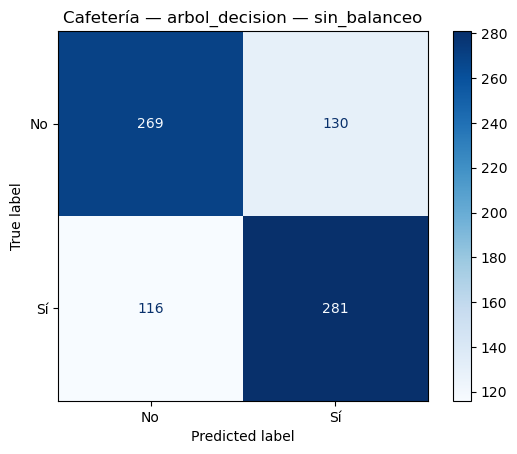

In [16]:
y_pred = mejor_modelo.predict(X_test)
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=['No', 'Sí'], zero_division=0))
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1], display_labels=['No', 'Sí'], cmap='Blues'
)
plt.title(f'{CUPON} — {ALGORITMO} — {variante_elegida}')
plt.show()


In [17]:
def metricas_modelo(y_true, y_pred):
    return {
        'precision_si': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'recall_si': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'f1_si': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'recall_minoritaria': recall_score(y_true, y_pred, pos_label=clase_minoritaria, zero_division=0),
    }

comparacion_train_test = pd.DataFrame({
    'train': metricas_modelo(y_train, mejor_modelo.predict(X_train)),
    'test': metricas_modelo(y_test, y_pred),
}).T
display(comparacion_train_test.round(3))


,precision_si,recall_si,f1_si,f1_macro,recall_minoritaria
train,0.727,0.728,0.727,0.728,0.728
test,0.684,0.708,0.696,0.691,0.708


In [18]:
pred_sin_balanceo = decision_tree_grid.best_estimator_.predict(X_test)
resultados = pd.DataFrame([{
    'cupon': CUPON, 'algoritmo': ALGORITMO, 'variante': 'sin_balanceo',
    'elegida_por_cv': variante_elegida == 'sin_balanceo',
    'f1_macro_cv': decision_tree_grid.best_score_, 'clase_minoritaria': clase_minoritaria,
    **metricas_modelo(y_test, pred_sin_balanceo),
}])


In [19]:
display(resultados.round(3))


,cupon,algoritmo,variante,elegida_por_cv,f1_macro_cv,clase_minoritaria,precision_si,recall_si,f1_si,f1_macro,recall_minoritaria
0,Cafetería,arbol_decision,sin_balanceo,True,0.71,1,0.684,0.708,0.696,0.691,0.708


En test, la precision de aceptacion fue 0.6837, el recall 0.7078 y el F1 0.6955. El F1 macro fue 0.6909. La clase ligeramente minoritaria es aceptacion, con 397 casos en test; su recall coincide con el recall de aceptacion.

La matriz contiene 281 aceptaciones y 269 rechazos correctos. Se predijo aceptacion en 130 rechazos reales, lo que puede producir ofertas irrelevantes; se omitieron 116 aceptaciones reales, que representan oportunidades perdidas.

El F1 macro del modelo ajustado sobre todo train fue aproximadamente 0.728, frente a 0.6909 en test. La diferencia es moderada y el resultado de test es cercano al de validacion. Esto no descarta errores ni garantiza el mismo desempeno en otra poblacion.


## 8. Interpretacion del modelo

Seguimos el enfoque de la practica: coeficientes para regresion, y reduccion de impureza y reglas para arboles/bosques. Describen asociaciones del modelo, no relaciones causales.


In [20]:
preprocesador_fit = mejor_modelo.named_steps['preprocesador']
modelo_fit = mejor_modelo.named_steps['model']
feature_names = preprocesador_fit.get_feature_names_out()


cat__frecuencia_cafeteria_nunca                       0.399427
cat__destino_Sin lugar urgente                        0.115929
cat__frecuencia_cafeteria_menos de 1                  0.112287
cat__misma_direccion_Sí                               0.071866
cat__hora_10:00 a.m.                                  0.048212
cat__vigencia_cupon_1 día                             0.044923
cat__hora_10:00 p.m.                                  0.029847
cat__genero_Masculino                                 0.027079
cat__vigencia_cupon_2 horas                           0.022591
cat__ocupacion_Estudiante                             0.018779
cat__frecuencia_restaurante_20_a_50_1 a 3             0.018473
cat__destino_Trabajo                                  0.016803
cat__ingreso_$50.000 - $62.499                        0.016295
cat__estado_civil_Unión libre                         0.014988
cat__educacion_Estudios universitarios sin título     0.010579
cat__educacion_Bachillerato completo                  0

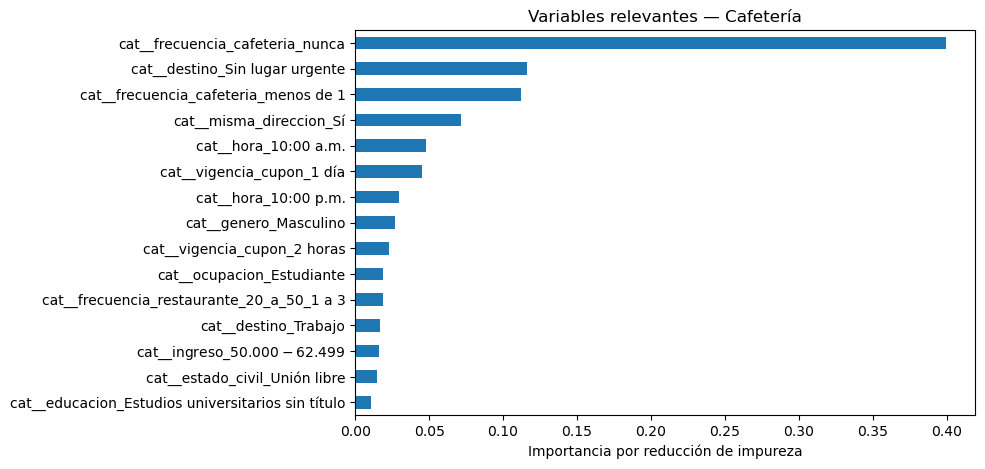

In [21]:
importancias = pd.Series(modelo_fit.feature_importances_, index=feature_names)
importancias = importancias.sort_values(ascending=False)
display(importancias.head(20))
importancias.head(15).sort_values().plot.barh(figsize=(8, 5))
plt.xlabel('Importancia por reducción de impureza')
plt.title(f'Variables relevantes — {CUPON}')
plt.show()


La categoria nunca de frecuencia_cafeteria concentra el 39.94% de la importancia por impureza y aparece en la primera division del arbol. Sumando sus categorias, frecuencia_cafeteria representa el 51.83%; le siguen destino con 13.27%, hora con 7.81%, misma_direccion con 7.19% y vigencia_cupon con 6.75%.

El arbol depende principalmente del habito de visitar cafeterias y del contexto del trayecto. Estas importancias describen como divide el modelo; no indican por si solas que una categoria aumente la aceptacion. Para conocer el sentido se revisan las reglas. La impureza puede favorecer variables con mas categorias y repartir importancia entre variables relacionadas.


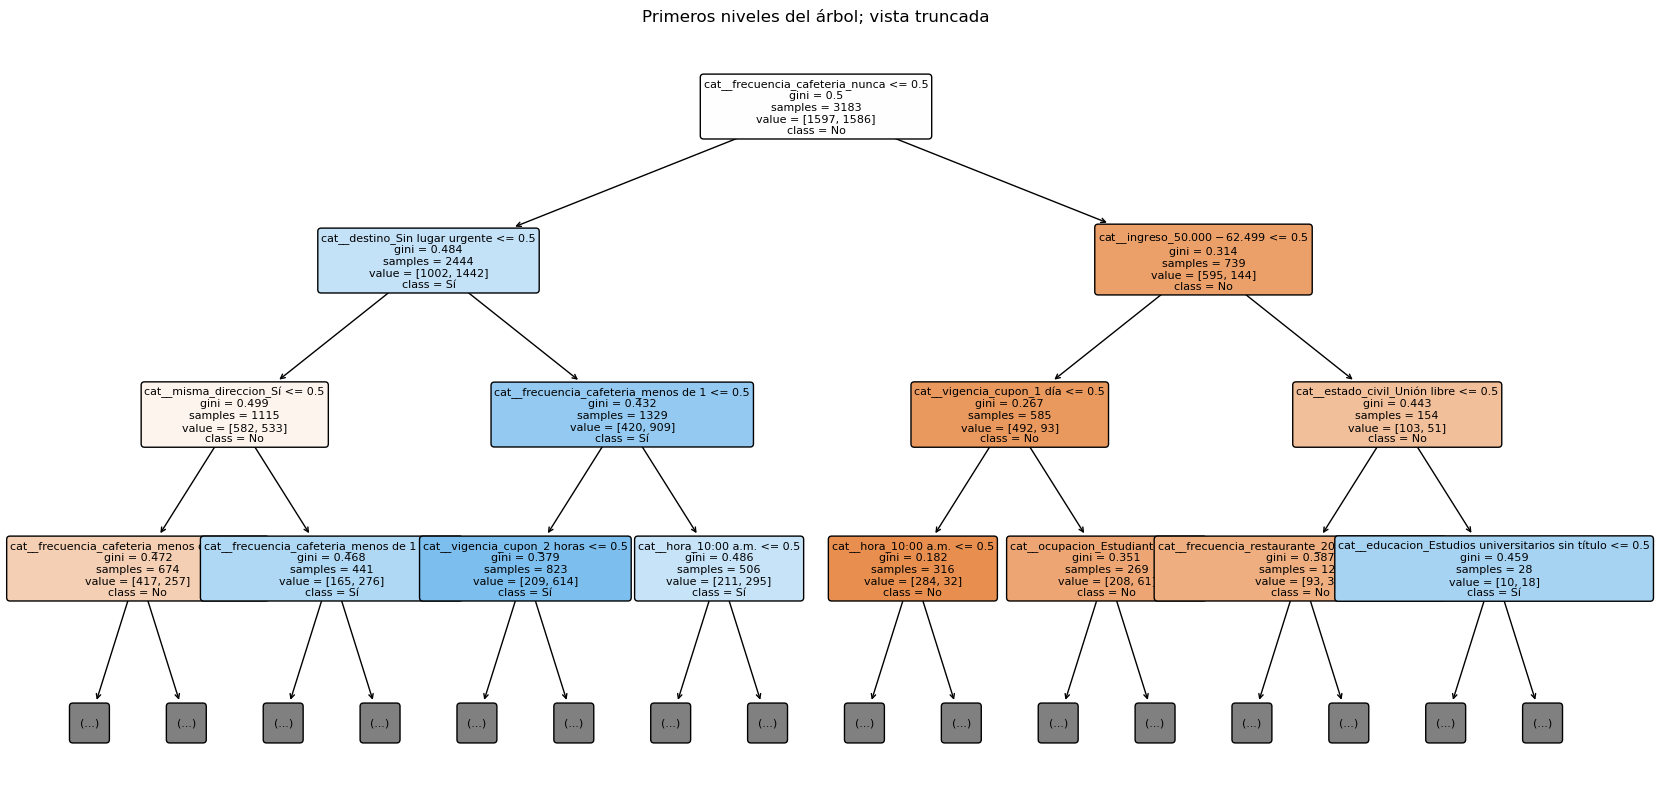

|--- cat__frecuencia_cafeteria_nunca <= 0.50
|   |--- cat__destino_Sin lugar urgente <= 0.50
|   |   |--- cat__misma_direccion_Sí <= 0.50
|   |   |   |--- cat__frecuencia_cafeteria_menos de 1 <= 0.50
|   |   |   |   |--- cat__vigencia_cupon_1 día <= 0.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- cat__vigencia_cupon_1 día >  0.50
|   |   |   |   |   |--- class: 1
|   |   |   |--- cat__frecuencia_cafeteria_menos de 1 >  0.50
|   |   |   |   |--- cat__genero_Masculino <= 0.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- cat__genero_Masculino >  0.50
|   |   |   |   |   |--- class: 0
|   |   |--- cat__misma_direccion_Sí >  0.50
|   |   |   |--- cat__frecuencia_cafeteria_menos de 1 <= 0.50
|   |   |   |   |--- cat__hora_10:00 p.m. <= 0.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- cat__hora_10:00 p.m. >  0.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- cat__frecuencia_cafeteria_menos de 1 >  0.50
|   |   |   |   |--- cat__destino_Trabajo <= 0.50
|  

In [22]:
plt.figure(figsize=(20, 10))
plot_tree(modelo_fit, feature_names=list(feature_names), class_names=['No', 'Sí'],
          max_depth=3, filled=True, rounded=True, fontsize=8)
plt.title('Primeros niveles del árbol; vista truncada')
plt.show()
print(export_text(modelo_fit, feature_names=list(feature_names), max_depth=4))


Dos reglas obtenidas del arbol de Cafeteria son:

1. Si la persona visita cafeterias al menos una vez al mes, no tiene un destino urgente y el cupon dura un dia, el arbol predice aceptacion.
2. Si visita cafeterias al menos una vez al mes, va a casa o al trabajo, el establecimiento no queda en la misma direccion y el cupon dura dos horas, el arbol predice rechazo.

Estas reglas resumen ramas del arbol ajustado y permiten explicar recomendaciones a Ruta Alpes. No son reglas universales: hay errores en test y las divisiones pueden cambiar con otra muestra. La figura muestra solo los primeros niveles.


## 9. Guardar resultados

Persistimos el pipeline, como en la practica 7, y las metricas para integrar despues. Este modelo se ajusto solo en train. El ganador de cada cupon se reajustara con todos sus datos etiquetados al generar el CSV externo.


In [23]:
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
resultados.to_csv(RUTA_RESULTADOS / 'metricas_test.csv', index=False, encoding='utf-8-sig')
resultados_cv.to_csv(RUTA_RESULTADOS / 'cv_sin_balanceo.csv', index=False, encoding='utf-8-sig')
particion = pd.concat([
    pd.DataFrame({'id_fila': X_train.index, 'conjunto': 'train'}),
    pd.DataFrame({'id_fila': X_test.index, 'conjunto': 'test'}),
], ignore_index=True)
particion.to_csv(RUTA_RESULTADOS / 'particion.csv', index=False)
pd.DataFrame({'id_fila': X_test.index, 'real': y_test.to_numpy(), 'prediccion': y_pred}).to_csv(
    RUTA_RESULTADOS / 'predicciones_test_interno.csv', index=False
)
joblib.dump(mejor_modelo, RUTA_RESULTADOS / 'pipeline_evaluado.joblib')


['resultados\\cafeteria_arbol_decision\\pipeline_evaluado.joblib']

In [24]:
importancias.rename('importancia').to_csv(RUTA_RESULTADOS / 'importancias.csv', encoding='utf-8-sig')


## 10. Analisis de resultados

**1. Caracteristicas relacionadas con la aceptacion**

La frecuencia de visitas concentra el 51.83% de la importancia agrupada del arbol. Destino, hora, direccion y vigencia complementan sus reglas. El habito de consumo y la conveniencia del trayecto son los factores mas destacados en este modelo.

**2. Variables redundantes o poco informativas**

Se excluyeron la variable constante de tiempo mayor a 5 minutos y direccion_opuesta, que era el complemento de misma_direccion. vehiculo tenia cerca del 99.15% de faltantes. Las otras variables de tiempo expresan condiciones distintas y no se eliminaron solo por estar relacionadas. Una importancia pequena no basta para descartar un predictor sin una comparacion en validacion.

**3. Diferencias de desempeno**

Los tres modelos de Cafeteria usaron la misma particion. La comparacion registrada es:

| Modelo | F1 macro CV | Precision de aceptacion | Recall de aceptacion | F1 de aceptacion | F1 macro test |
|---|---:|---:|---:|---:|---:|
| Regresion logistica | 0.7193 | 0.6950 | 0.7406 | 0.7171 | 0.7083 |
| Arbol de decision | 0.7099 | 0.6837 | 0.7078 | 0.6955 | 0.6909 |
| Random Forest | 0.7482 | 0.7160 | 0.7431 | 0.7293 | 0.7248 |


Random Forest se selecciona para Cafeteria por su mayor F1 macro en validacion cruzada: 0.7482. Test confirma el orden observado, con 0.7248 para el bosque, 0.7083 para la regresion y 0.6909 para el arbol. La regresion ofrece una alternativa mas sencilla y tiene una brecha menor entre entrenamiento y test. El bosque presenta el mayor sobreajuste y la diferencia entre modelos no se ha sometido a una prueba de significancia.

Los notebooks de Restaurante aun no tienen resultados. No se puede afirmar cual cupon tiene mejor desempeno ni atribuir una diferencia a sus caracteristicas hasta evaluarlos.

**4. Balanceo en Restaurante**

Este notebook no evalua SMOTE y Cafeteria esta casi equilibrada. Todavia no hay resultados de Restaurante con y sin balanceo, por lo que no se puede recomendar la tecnica con evidencia. Esa conclusion requiere comparar el F1 macro, el F1 de aceptacion y el recall de la clase minoritaria en sus experimentos, con el test sin remuestrear.

**5. Reglas, utilidad y limitacion**

El arbol de Cafeteria predice aceptacion para visitas al menos mensuales, destino sin urgencia y vigencia de un dia. Predice rechazo para visitas al menos mensuales, destino casa o trabajo, establecimiento en otra direccion y vigencia de dos horas. Estas reglas explican decisiones concretas, pero no prueban causas ni garantizan aciertos en nuevos conductores. El bosque no tiene una unica regla equivalente para todas sus predicciones.

**6. Integracion en la aplicacion**

La aplicacion puede reunir las variables disponibles del trayecto y los habitos autorizados, aplicar el pipeline y estimar la probabilidad de aceptar cada oferta. Las oportunidades se pueden ordenar con esa estimacion, considerando cercania, vigencia y frecuencia de notificaciones. Debe evitarse distraer al conductor. El umbral de esta evaluacion es 0.5; cualquier cambio requiere validacion y no debe ajustarse con este test.

**7. Limitaciones de personalizar por perfil demografico**

El modelo puede tratar de manera distinta a personas por edad, genero, estado civil o ingreso, aunque sus necesidades individuales sean diferentes. Puede excluir ofertas utiles, repetir estereotipos y depender de datos privados o desactualizados. No se midieron los errores por grupo, asi que estas metricas globales no demuestran equidad. La probabilidad predicha tampoco garantiza una compra ni demuestra el efecto de enviar el cupon.

**8. Fuentes de sesgo e implicaciones**

La muestra puede representar de manera desigual a los conductores y las respuestas pueden reflejar sesgos previos. La imputacion por moda refuerza categorias frecuentes. La particion por filas no garantiza independencia entre conductores, porque id_fila no identifica personas. Ademas, otras variables pueden actuar como sustitutos del perfil demografico.

Antes de usarlo se deben revisar precision y recall por grupo junto con sus tamanos, proteger los datos personales y vigilar cambios en el comportamiento. Si se aplicara a precios dinamicos, estas diferencias podrian generar cobros desiguales; el desempeno obtenido para cupones no justifica trasladarlo directamente a ese uso.
